<a href="https://colab.research.google.com/github/An4PDM/Disciplina-IA-2026-02/blob/main/Atividade_AutoML_flaml_vs_autosklearn_Ana_Paula_6A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## **AutoML no Iris: FLAML x Auto-Sklearn**

### 1. Importação e instalação das bibliotecas

O FLAML roda direto no Python do Colab. O auto-sklearn não instala no Python 3.11/3.12 do Colab (ele exige scikit-learn 0.24, que só tem pacote pronto até o Python 3.9). Por isso, ele roda num ambiente separado com Python 3.9, criado com o `uv`, e se comunica com este notebook por arquivos (os mesmos dados de treino/teste entram e as previsões voltam).

In [1]:
!pip install -q "flaml[automl]"

In [2]:
import os
import json
import time
import threading
import subprocess
import warnings
import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

from flaml import AutoML

warnings.filterwarnings('ignore')

SEED = 42
TIME_BUDGET = 60      # orçamento total (s), igual para os dois frameworks (o auto-sklearn exige no mínimo 30)
PER_RUN_LIMIT = 10    # auto-sklearn: tempo máximo por modelo (segundos)
N_JOBS = 1            # mesmo paralelismo nos dois, para comparação justa

class MonitorMemoria:
    # amostra a memória (RSS) do processo e de seus filhos a cada 0,2 s e guarda o pico
    def __init__(self, intervalo=0.2):
        self.intervalo = intervalo
        self.pico_mb = 0.0
        self._parar = threading.Event()
        self._proc = psutil.Process()

    def _loop(self):
        while not self._parar.is_set():
            try:
                total = self._proc.memory_info().rss
                total += sum(c.memory_info().rss for c in self._proc.children(recursive=True))
                self.pico_mb = max(self.pico_mb, total / 1024**2)
            except psutil.Error:
                pass
            time.sleep(self.intervalo)

    def __enter__(self):
        self._t = threading.Thread(target=self._loop, daemon=True)
        self._t.start()
        return self

    def __exit__(self, *args):
        self._parar.set()
        self._t.join()

### 2. Carregando o dataset e análise de dados

In [3]:
iris = load_iris(as_frame=True)
df = iris.frame

print(df.shape)
print(df.head())

(150, 5)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None


In [5]:
print('Dados nulos: ')
print(df.isnull().sum())

Dados nulos: 
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [6]:
print('Duplicados: ')
print(df.duplicated().sum())
# As linhas duplicadas foram mantidas para preservar as 150 amostras do dataset clássico.

Duplicados: 
1


### 3. Transformação numérica

In [7]:
# No Iris a variável alvo já é numérica (0, 1, 2); só conferimos o significado de cada código
alvo = 'target'
for codigo, nome in enumerate(iris.target_names):
    print(codigo, ':', nome)

print(df.dtypes)

0 : setosa
1 : versicolor
2 : virginica
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
dtype: object


### 4. Divisão X e y, treino e teste

In [8]:
X = df.drop(columns=[alvo])
y = df[alvo]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print('Classes no treino:', y_train.value_counts().sort_index().to_dict())
print('Classes no teste :', y_test.value_counts().sort_index().to_dict())

Treino: (120, 4) | Teste: (30, 4)
Classes no treino: {0: 40, 1: 40, 2: 40}
Classes no teste : {0: 10, 1: 10, 2: 10}


In [9]:
# Salva a MESMA divisão em arquivos, para o auto-sklearn (ambiente separado) usar os mesmos dados
os.makedirs('askl_data', exist_ok=True)
X_train.to_csv('askl_data/X_train.csv', index=False)
X_test.to_csv('askl_data/X_test.csv', index=False)
y_train.to_frame().to_csv('askl_data/y_train.csv', index=False)
y_test.to_frame().to_csv('askl_data/y_test.csv', index=False)
print(os.listdir('askl_data'))

['X_train.csv', 'y_train.csv', 'X_test.csv', 'y_test.csv']


### 5. FLAML (com time_budget)

In [10]:
automl = AutoML()
arquivo_log = 'flaml_iris.log'

configuracao = {
    'time_budget': TIME_BUDGET,
    'task': 'classification',
    'metric': 'accuracy',
    'estimator_list': ['lgbm', 'rf', 'extra_tree', 'xgboost', 'lrl1'],
    'seed': SEED,
    'n_jobs': N_JOBS,
    'log_file_name': arquivo_log,
    'verbose': 1,
}

with MonitorMemoria() as mon_flaml:
    inicio = time.perf_counter()
    automl.fit(X_train=X_train, y_train=y_train, **configuracao)
    tempo_flaml = time.perf_counter() - inicio
mem_flaml = mon_flaml.pico_mb

print('Tempo real de execução (s):', round(tempo_flaml, 2))

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


Tempo real de execução (s): 60.06


In [11]:
# Inspeção do modelo escolhido pelo FLAML
with open(arquivo_log) as f:
    configs_flaml = sum(1 for linha in f if linha.strip())

print('Melhor estimador:', automl.best_estimator)
print('Melhores parâmetros:', automl.best_config)
print('Melhor erro na validação (1 - acurácia):', automl.best_loss)
print('Configurações avaliadas:', configs_flaml)
print('Modelo final:', automl.model.estimator)

Melhor estimador: lrl1
Melhores parâmetros: {'C': np.float64(1.0)}
Melhor erro na validação (1 - acurácia): 0.024999999999999977
Configurações avaliadas: 6
Modelo final: LogisticRegression(C=np.float64(1.0), n_jobs=1, penalty='l1',
                   random_state=10242048, solver='saga')


In [12]:
# Importância das variáveis (só faz sentido direto para modelos baseados em árvores)
try:
    importancias = pd.Series(automl.feature_importances_, index=automl.feature_names_in_)
    print(importancias.sort_values(ascending=False))
except Exception:
    print(f'O modelo escolhido ({automl.best_estimator}) não fornece importâncias simples por variável.')

O modelo escolhido (lrl1) não fornece importâncias simples por variável.


### 6. Auto-Sklearn (ambiente separado com Python 3.9)

#### 6.1 Criando o ambiente

In [13]:
%%bash
rm -rf askl_env
pip install -q uv
uv python install 3.9
uv venv askl_env --python 3.9
export PATH="$PWD/askl_env/bin:$PATH"
uv pip install -q --python askl_env/bin/python swig "setuptools<70" wheel cython "numpy<1.24"
uv pip install -q --python askl_env/bin/python --no-build-isolation auto-sklearn pandas psutil
askl_env/bin/python -c "import autosklearn; print('auto-sklearn', autosklearn.__version__, 'instalado')"

auto-sklearn 0.15.0 instalado


Installed Python 3.9.25 in 1.48s
 + cpython-3.9.25-linux-x86_64-gnu (python3.9)
Using CPython 3.9.25
Creating virtual environment at: askl_env
Activate with: source askl_env/bin/activate


#### 6.2 Script do auto-sklearn (lê os dados salvos, treina e grava os resultados)

In [14]:
%%writefile askl_script.py
import json
import time
import sys
import threading
import psutil
import pandas as pd
import autosklearn.classification as ac
from sklearn.metrics import accuracy_score

class MonitorMemoria:
    # amostra a memória (RSS) do processo e de seus filhos a cada 0,2 s e guarda o pico
    def __init__(self, intervalo=0.2):
        self.intervalo = intervalo
        self.pico_mb = 0.0
        self._parar = threading.Event()
        self._proc = psutil.Process()

    def _loop(self):
        while not self._parar.is_set():
            try:
                total = self._proc.memory_info().rss
                total += sum(c.memory_info().rss for c in self._proc.children(recursive=True))
                self.pico_mb = max(self.pico_mb, total / 1024**2)
            except psutil.Error:
                pass
            time.sleep(self.intervalo)

    def __enter__(self):
        self._t = threading.Thread(target=self._loop, daemon=True)
        self._t.start()
        return self

    def __exit__(self, *args):
        self._parar.set()
        self._t.join()

TIME_BUDGET = int(sys.argv[1])
PER_RUN_LIMIT = int(sys.argv[2])
SEED = int(sys.argv[3])

X_train = pd.read_csv('askl_data/X_train.csv')
X_test = pd.read_csv('askl_data/X_test.csv')
y_train = pd.read_csv('askl_data/y_train.csv').iloc[:, 0]
y_test = pd.read_csv('askl_data/y_test.csv').iloc[:, 0]

modelo = ac.AutoSklearnClassifier(
    time_left_for_this_task=TIME_BUDGET,
    per_run_time_limit=PER_RUN_LIMIT,
    seed=SEED,
    n_jobs=1,
    memory_limit=3072,
)

with MonitorMemoria() as mon:
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    tempo = time.perf_counter() - inicio

y_pred = modelo.predict(X_test)
pd.DataFrame({'pred': y_pred}).to_csv('askl_data/askl_pred.csv', index=False)

# texto com os pipelines do ensemble
linhas = []
for model_id, info in modelo.show_models().items():
    linhas.append(f"modelo {model_id} | peso {info['ensemble_weight']:.2f} | custo {info['cost']:.4f}")
    linhas.append(f"  pré-processador de dados : {type(info['data_preprocessor'].choice).__name__}")
    linhas.append(f"  pré-processador de features: {type(info['feature_preprocessor'].choice).__name__}")
    linhas.append(f"  classificador            : {info['sklearn_classifier']}")
    linhas.append('')

pico = mon.pico_mb

resultado = {
    'tempo_s': tempo,
    'configuracoes': int(len(modelo.cv_results_['mean_test_score'])),
    'modelos_no_ensemble': int(len(modelo.get_models_with_weights())),
    'pico_memoria_mb': pico,
    'acuracia_teste': float(accuracy_score(y_test, y_pred)),
    'estatisticas': modelo.sprint_statistics(),
    'leaderboard': modelo.leaderboard(detailed=False).to_string(),
    'modelos': '\n'.join(linhas),
}
with open('askl_data/askl_result.json', 'w') as f:
    json.dump(resultado, f)
print('auto-sklearn finalizado.')

Writing askl_script.py


#### 6.3 Executando o auto-sklearn

In [15]:
AUTOSKLEARN_OK = False
proc = subprocess.run(
    ['askl_env/bin/python', 'askl_script.py', str(TIME_BUDGET), str(PER_RUN_LIMIT), str(SEED)],
    capture_output=True, text=True
)
print(proc.stdout[-1500:])
if proc.returncode == 0 and os.path.exists('askl_data/askl_result.json'):
    AUTOSKLEARN_OK = True
    with open('askl_data/askl_result.json') as f:
        res_askl = json.load(f)
    print('Tempo real de execução (s):', round(res_askl['tempo_s'], 2))
else:
    print('Falha ao executar o auto-sklearn:')
    print(proc.stderr[-3000:])

auto-sklearn finalizado.

Tempo real de execução (s): 62.24


In [16]:
# Inspeção do ensemble gerado pelo auto-sklearn
if AUTOSKLEARN_OK:
    print(res_askl['estatisticas'])
    print()
    print(res_askl['leaderboard'])
    print()
    print(res_askl['modelos'])

auto-sklearn results:
  Dataset name: fdf34d4f-de99-11f1-864f-77ee4656169d
  Metric: accuracy
  Best validation score: 0.975000
  Number of target algorithm runs: 25
  Number of successful target algorithm runs: 15
  Number of crashed target algorithm runs: 9
  Number of target algorithms that exceeded the time limit: 1
  Number of target algorithms that exceeded the memory limit: 0


          rank  ensemble_weight                type   cost  duration
model_id                                                            
2            1             0.10       random_forest  0.025  1.782718
3            2             0.08       random_forest  0.025  1.886473
5            3             0.04       random_forest  0.025  1.944942
21           4             0.08         extra_trees  0.025  1.607859
23           5             0.08         extra_trees  0.025  2.067670
8            6             0.04       random_forest  0.050  2.746547
9            7             0.10       random_forest  0.050  

### 7. Previsões e avaliação (acurácia e classification_report)

In [17]:
previsoes = {'FLAML': automl.predict(X_test)}
if AUTOSKLEARN_OK:
    previsoes['Auto-Sklearn'] = pd.read_csv('askl_data/askl_pred.csv')['pred'].values

for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))


FLAML — Acurácia: 100.00%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Auto-Sklearn — Acurácia: 96.67%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### 8. Matriz de confusão

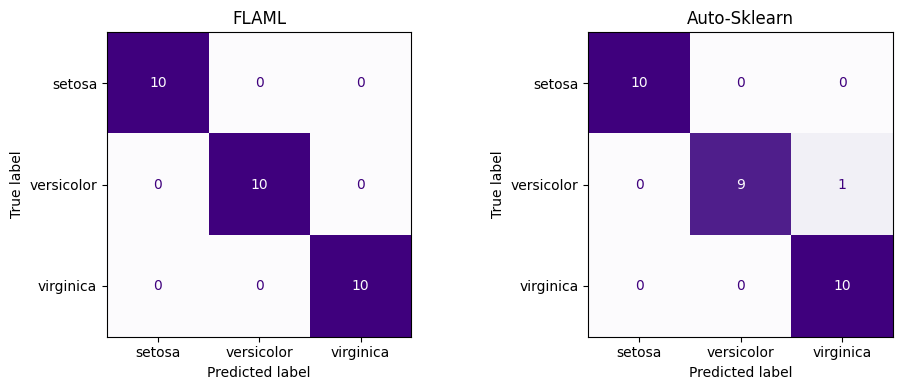

In [18]:
fig, axes = plt.subplots(1, len(previsoes), figsize=(5 * len(previsoes), 4), squeeze=False)
for ax, (nome, y_pred) in zip(axes[0], previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
        display_labels=iris.target_names, ax=ax, colorbar=False, cmap='Purples')
    ax.set_title(nome)
plt.tight_layout()
plt.show()

### 9. Comparação final: desempenho e custo computacional

In [19]:
linhas = [{
    'Framework': 'FLAML',
    'Acurácia (teste)': accuracy_score(y_test, previsoes['FLAML']),
    'Erros no teste': int((y_test.values != previsoes['FLAML']).sum()),
    'Tempo real (s)': tempo_flaml,
    'Configurações avaliadas': configs_flaml,
    'Pico de memória (MB)': mem_flaml,
    'Modelo escolhido': automl.best_estimator,
}]

if AUTOSKLEARN_OK:
    linhas.append({
        'Framework': 'Auto-Sklearn',
        'Acurácia (teste)': accuracy_score(y_test, previsoes['Auto-Sklearn']),
        'Erros no teste': int((y_test.values != previsoes['Auto-Sklearn']).sum()),
        'Tempo real (s)': res_askl['tempo_s'],
        'Configurações avaliadas': res_askl['configuracoes'],
        'Pico de memória (MB)': res_askl['pico_memoria_mb'],
        'Modelo escolhido': f"ensemble ({res_askl['modelos_no_ensemble']} modelos)",
    })

tabela = pd.DataFrame(linhas)
tabela.round(4)

,Framework,Acurácia (teste),Erros no teste,Tempo real (s),Configurações avaliadas,Pico de memória (MB),Modelo escolhido
0,FLAML,1.0000,0,60.0566,6,687.4648,lrl1
1,Auto-Sklearn,0.9667,1,62.2422,25,431.2930,ensemble (14 modelos)


**Observação sobre a memória:** o pico é o maior valor de memória (RSS) amostrado a cada 0,2 s durante o `fit`, somando o processo e seus subprocessos. O FLAML foi medido dentro do processo do notebook, que já ocupa algumas centenas de MB só por carregar o Colab e as bibliotecas; por isso o valor dele inclui essa memória-base. O auto-sklearn foi medido no próprio processo, separado do notebook. Use os valores como ordem de grandeza, não como comparação exata.

## 10. Conclusão

- Desempenho: O FLAML apresentou o melhor resultado, alcançando 100% de acurácia, enquanto o Auto-Sklearn obteve 96,67%.

- Custo computacional: Os dois apresentaram tempos de execução semelhantes. O FLAML avaliou menos configurações (6), enquanto o Auto-Sklearn avaliou 25. O Auto-Sklearn apresentou menor pico de memória.

- Interpretabilidade: O FLAML apresentou maior simplicidade, utilizando um único modelo de Regressão Logística. Já o Auto-Sklearn gerou um ensemble de 14 modelos, tornando sua estrutura mais complexa e menos interpretável.